Dimensões do arquivo MCA: (118036, 21)

Primeiras linhas:
   indice_original     MCA_1     MCA_2     MCA_3     MCA_4     MCA_5  \
0                0 -0.058687  0.087536 -0.198181  0.148724 -0.135594   
1                1 -0.060935  0.336220 -0.141791 -0.007353 -0.002461   
2                2 -0.062856  0.184424 -0.118277 -0.091185  0.095571   
3                3 -0.045618  0.810185 -0.199863  0.067817 -0.038888   
4                4 -0.031681  0.033282 -0.008753 -0.325711  0.352791   

      MCA_6     MCA_7     MCA_8     MCA_9  ...    MCA_11    MCA_12    MCA_13  \
0 -0.073126  0.003523 -0.199525  0.295610  ... -0.047003  0.191852  0.113197   
1 -0.032119  0.017430  0.233641 -0.107655  ... -0.280788  0.174561 -0.055403   
2  0.061738  0.004565  0.147833 -0.163209  ... -0.241488  0.251893 -0.086917   
3 -0.020754  0.014097  0.039749 -0.349031  ...  0.127378  0.030143  0.044158   
4  0.215634 -0.005061  0.326125 -0.229856  ...  0.007319  0.354320  0.060076   

     MCA_14    MCA_15    MCA

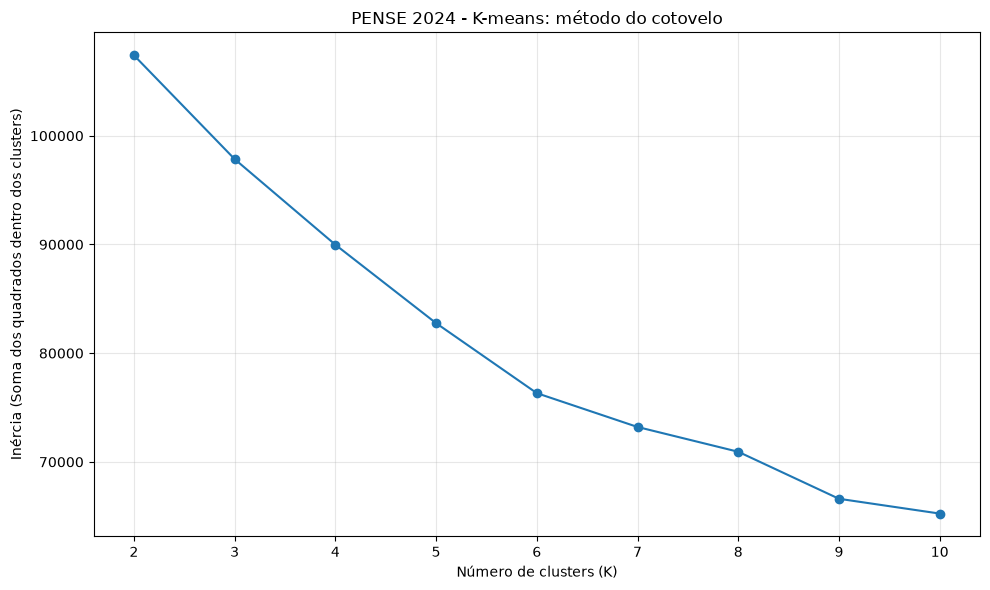

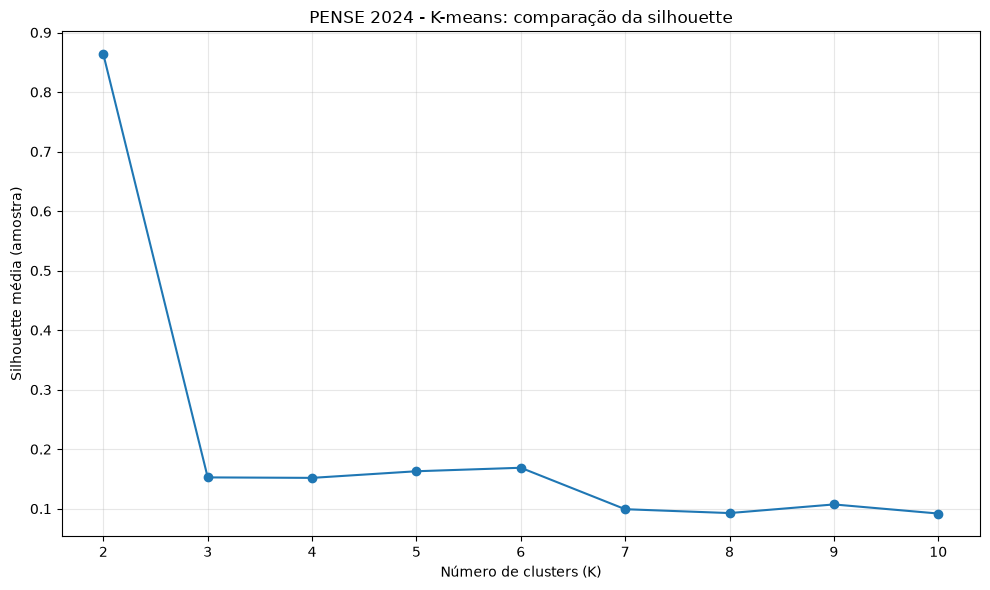


Executando o K-means final com K=2...

Tamanho de cada cluster:
Cluster
0       519
1    117517

Percentual por cluster:
Cluster
0     0.44
1    99.56

Inércia do modelo final: 107406.4828

Nenhum arquivo externo foi salvo.
O resultado df_resultado está disponível na memória do notebook.


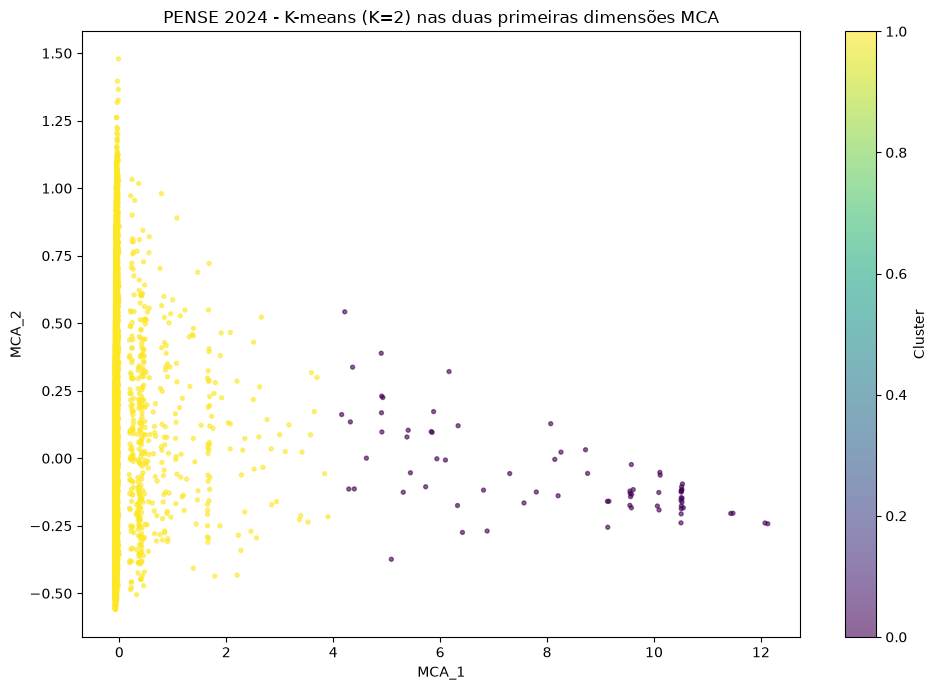


Observação: o gráfico MCA_1 × MCA_2 é apenas uma projeção
visual. Os clusters foram calculados usando todas as dimensões MCA.


In [1]:
# ============================================================
# PENSE 2024 - CLUSTERIZAÇÃO COM K-MEANS
# Entrada: coordenadas produzidas pelo MCA (arquivo 08)
#
# O notebook:
#   1. Lê as coordenadas MCA.
#   2. Avalia valores de K usando método do cotovelo e silhouette.
#   3. Exibe os gráficos na saída do notebook (não salva PNG).
#   4. Executa K-means com o K escolhido abaixo.
#   5. Mantém os clusters em memória, sem salvar arquivo externo.
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# ------------------------------------------------------------
# 1. CAMINHOS E PARÂMETROS
# ------------------------------------------------------------

arquivo = Path(
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/"
    "02_Tratamento_dados_database_PENSE_2024/"
    "02_Scripts_tratamento_dados_PENSE_2024/"
    "08_PENSE2024_MCA_COORDENADAS.feather"
)

# Os resultados ficam apenas na memória do notebook.
# Nenhum arquivo externo de clusters será gravado.

# K final usado para gerar os clusters.
# Comece com 5 como valor exploratório e ajuste após analisar
# os gráficos do cotovelo e da silhouette.
K_FINAL = 2

# Avaliar os valores de K abaixo.
K_MIN = 2
K_MAX = 10

# Silhouette em amostra para reduzir o custo computacional.
# Com cerca de 118 mil linhas, calcular silhouette em toda a
# base pode ser demorado. A amostra é usada apenas para avaliação.
TAMANHO_AMOSTRA_SILHOUETTE = 10000

RANDOM_STATE = 42

# ------------------------------------------------------------
# 2. LER AS COORDENADAS DO MCA
# ------------------------------------------------------------

df_mca = pd.read_feather(arquivo)

print("Dimensões do arquivo MCA:", df_mca.shape)
print("\nPrimeiras linhas:")
print(df_mca.head())

# A coluna índice_original é um identificador, não uma dimensão
# para calcular distâncias. Portanto, não deve entrar no K-means.
coluna_id = "indice_original" if "indice_original" in df_mca.columns else None

colunas_mca = [
    coluna for coluna in df_mca.columns
    if coluna.startswith("MCA_")
]

if not colunas_mca:
    raise ValueError(
        "Nenhuma coluna começando com 'MCA_' foi encontrada. "
        "Confira o arquivo de coordenadas."
    )

X = df_mca[colunas_mca].copy()

# Garantir valores numéricos.
X = X.apply(pd.to_numeric, errors="coerce")

# K-means não aceita valores ausentes ou infinitos.
if not np.isfinite(X.to_numpy(dtype=float)).all():
    raise ValueError(
        "As coordenadas MCA contêm valores ausentes ou infinitos. "
        "Verifique o arquivo 08 antes de executar o K-means."
    )

X_array = X.to_numpy(dtype=np.float64)

print("\nNúmero de observações:", X_array.shape[0])
print("Número de dimensões MCA usadas:", X_array.shape[1])
print("Colunas usadas:", colunas_mca)

# ------------------------------------------------------------
# 3. AVALIAR DIFERENTES VALORES DE K
# ------------------------------------------------------------

valores_k = list(range(K_MIN, K_MAX + 1))
inertias = []
silhouettes = []

# Gerar uma amostra fixa para comparar a silhouette entre K.
rng = np.random.default_rng(RANDOM_STATE)
n_amostra = min(TAMANHO_AMOSTRA_SILHOUETTE, len(X_array))
indices_amostra = rng.choice(len(X_array), size=n_amostra, replace=False)
X_silhouette = X_array[indices_amostra]

for k in valores_k:
    print(f"Avaliando K={k}...")

    modelo_teste = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=RANDOM_STATE
    )

    rotulos = modelo_teste.fit_predict(X_array)
    inertias.append(modelo_teste.inertia_)

    # Silhouette calculada sobre a mesma amostra para cada K.
    rotulos_amostra = rotulos[indices_amostra]
    score_silhouette = silhouette_score(
        X_silhouette,
        rotulos_amostra
    )
    silhouettes.append(score_silhouette)

resultados_k = pd.DataFrame({
    "K": valores_k,
    "Inercia": inertias,
    "Silhouette_amostra": silhouettes
})

print("\nResultados da avaliação de K:")
print(resultados_k.round(4).to_string(index=False))

# ------------------------------------------------------------
# 4. GRÁFICO DO COTOVELO (INÉRCIA)
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))
plt.plot(valores_k, inertias, marker="o")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inércia (Soma dos quadrados dentro dos clusters)")
plt.title("PENSE 2024 - K-means: método do cotovelo")
plt.xticks(valores_k)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. GRÁFICO DA SILHOUETTE
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))
plt.plot(valores_k, silhouettes, marker="o")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Silhouette média (amostra)")
plt.title("PENSE 2024 - K-means: comparação da silhouette")
plt.xticks(valores_k)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# A silhouette varia de -1 a 1. Valores maiores geralmente
# indicam clusters mais separados, mas o resultado também deve
# ser interpretável e útil para o objetivo do estudo.

# ------------------------------------------------------------
# 6. EXECUTAR O MODELO FINAL
# ------------------------------------------------------------

if K_FINAL not in valores_k:
    raise ValueError(
        f"K_FINAL={K_FINAL} não está na faixa avaliada "
        f"({K_MIN} a {K_MAX}). Ajuste os parâmetros no início."
    )

print(f"\nExecutando o K-means final com K={K_FINAL}...")

modelo_final = KMeans(
    n_clusters=K_FINAL,
    init="k-means++",
    n_init=20,
    random_state=RANDOM_STATE
)

clusters = modelo_final.fit_predict(X_array)

# ------------------------------------------------------------
# 7. MONTAR O RESULTADO EM MEMÓRIA (SEM GRAVAR ARQUIVO)
# ------------------------------------------------------------

df_resultado = pd.DataFrame()

if coluna_id:
    df_resultado[coluna_id] = df_mca[coluna_id]

df_resultado["Cluster"] = clusters

# Também incluir as coordenadas MCA facilita análises e gráficos
# posteriores. Não incluir aqui a tabela de avaliação de K.
for coluna in colunas_mca:
    df_resultado[coluna] = df_mca[coluna].to_numpy()

# Não usar to_feather(), to_csv() ou outro comando de gravação.
# df_resultado permanece disponível para as próximas células.

print("\nTamanho de cada cluster:")
print(
    df_resultado["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Quantidade")
    .to_string()
)

print("\nPercentual por cluster:")
print(
    (df_resultado["Cluster"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
    .rename("Percentual (%)")
    .to_string()
)

print("\nInércia do modelo final:", round(modelo_final.inertia_, 4))
print("\nNenhum arquivo externo foi salvo.")
print("O resultado df_resultado está disponível na memória do notebook.")

# ------------------------------------------------------------
# 8. VISUALIZAÇÃO EXPLORATÓRIA DOS CLUSTERS NAS DUAS PRIMEIRAS
#    DIMENSÕES MCA (não salva imagem)
# ------------------------------------------------------------

if len(colunas_mca) >= 2:
    # Para manter o gráfico legível, usar uma amostra se a base for grande.
    max_pontos = 15000
    if len(df_resultado) > max_pontos:
        rng_plot = np.random.default_rng(RANDOM_STATE)
        idx_plot = rng_plot.choice(
            len(df_resultado), size=max_pontos, replace=False
        )
        df_plot = df_resultado.iloc[idx_plot]
    else:
        df_plot = df_resultado

    plt.figure(figsize=(10, 7))
    pontos = plt.scatter(
        df_plot["MCA_1"],
        df_plot["MCA_2"],
        c=df_plot["Cluster"],
        s=8,
        alpha=0.6
    )
    plt.xlabel("MCA_1")
    plt.ylabel("MCA_2")
    plt.title(
        f"PENSE 2024 - K-means (K={K_FINAL}) "
        "nas duas primeiras dimensões MCA"
    )
    plt.colorbar(pontos, label="Cluster")
    plt.tight_layout()
    plt.show()

print("\nObservação: o gráfico MCA_1 × MCA_2 é apenas uma projeção")
print("visual. Os clusters foram calculados usando todas as dimensões MCA.")


Dataset: (118036, 40)

Number of clusters: 2

CLUSTER SIZES


,Quantidade,Percentual (%)
Cluster,,
0,519,0.44
1,117517,99.56



EXAMPLE: CATEGORY PERCENTAGES BY CLUSTER
Variable: CAPITAL - indica se é município da capital


CAPITAL - indica se é município da capital,0,1
Cluster,,
0,41.8,58.2
1,48.2,51.8



EXAMPLE: DIFFERENCE FROM OVERALL POPULATION (percentage points)


CAPITAL - indica se é município da capital,0,1
Cluster,,
0,-6.4,6.4
1,0.0,-0.0



VARIABLES MOST ASSOCIATED WITH CLUSTER MEMBERSHIP


,Variavel,Qui_quadrado,Graus_liberdade,p_valor,Cramers_V,p_BH
23,"B12005 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",75183.23805,3,0.00000,0.79809,0.00000
25,"B12007 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",73856.78457,3,0.00000,0.79102,0.00000
24,"B12006 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",71826.24380,3,0.00000,0.78007,0.00000
22,"B12004 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",69960.90161,3,0.00000,0.76988,0.00000
18,"B07013 - NOS ÚLTIMOS 30 DIAS, você se sentiu a...",69911.19521,2,0.00000,0.76960,0.00000
20,"B07016 - NOS ÚLTIMOS 30 DIAS, você ameaçou, of...",68618.33445,2,0.00000,0.76245,0.00000
19,"B07009 - NOS ÚLTIMOS 30 DIAS, você esculachou,...",66788.26904,2,0.00000,0.75222,0.00000
26,"B12008 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",66551.90274,3,0.00000,0.75088,0.00000
21,B12003 - Quantos(as) amigos(as) próximos você ...,63900.30631,2,0.00000,0.73577,0.00000
17,"B07012A - NOS ÚLTIMOS 30 DIAS, quantas vezes a...",62549.20029,2,0.00000,0.72795,0.00000


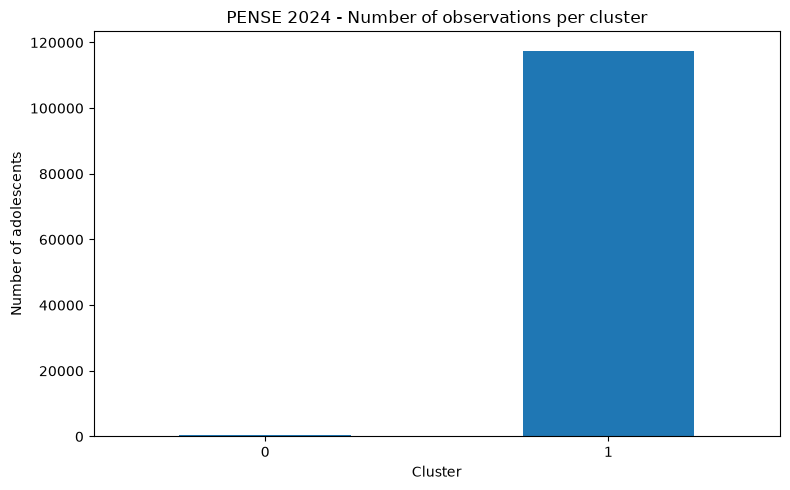

In [2]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

# --------------------------------------------------
# 1. FILE PATHS
# --------------------------------------------------

pasta = Path(
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/"
    "02_Tratamento_dados_database_PENSE_2024/"
    "02_Scripts_tratamento_dados_PENSE_2024"
)

arquivo_original = pasta / "07_PENSE2024_IDADE_13_A_17_CATEGORY.feather"

# Os clusters foram gerados na célula anterior e estão em memória.
# Não é necessário ler um arquivo externo de clusters.

# --------------------------------------------------
# 2. LOAD BOTH FILES
# --------------------------------------------------

df_original = pd.read_feather(arquivo_original)

if "df_resultado" not in globals():
    raise RuntimeError(
        "Execute primeiro a célula do K-means (célula anterior), "
        "que cria df_resultado em memória."
    )

df_kmeans = df_resultado

if len(df_original) != len(df_kmeans):
    raise ValueError(
        "Os arquivos têm números diferentes de linhas. "
        "Não associe os clusters às observações até verificar "
        "a correspondência dos registros."
    )

if "Cluster" not in df_kmeans.columns:
    raise ValueError("A coluna 'Cluster' não foi encontrada.")

# The previous K-means code preserves row order.
# Therefore, cluster labels can be assigned positionally.
df = df_original.copy()
df["Cluster"] = df_kmeans["Cluster"].to_numpy()

# Original categorical features only.
variaveis = [
    c for c in df_original.columns
    if c not in ["Cluster", "indice_original"]
]

# Normalize categorical missing values for the summaries.
for c in variaveis:
    df[c] = (
        df[c].astype("string")
        .fillna("Não informado")
        .replace(r"^\s*$", "Não informado", regex=True)
    )

print("Dataset:", df.shape)
print("\nNumber of clusters:", df["Cluster"].nunique())

# --------------------------------------------------
# 3. CLUSTER SIZES
# --------------------------------------------------

tamanho_clusters = (
    df["Cluster"].value_counts()
    .sort_index()
    .rename("Quantidade")
    .to_frame()
)

tamanho_clusters["Percentual (%)"] = (
    tamanho_clusters["Quantidade"] / len(df) * 100
)

print("\nCLUSTER SIZES")
display(tamanho_clusters.round(2))

# --------------------------------------------------
# 4. CATEGORY PROFILE FOR EACH CLUSTER
# --------------------------------------------------
# Each cell represents the percentage of a category
# within that cluster, for that particular variable.

perfis = {}

for var in variaveis:
    tabela = pd.crosstab(
        df["Cluster"],
        df[var],
        normalize="index"
    ) * 100

    perfis[var] = tabela

print("\nEXAMPLE: CATEGORY PERCENTAGES BY CLUSTER")
# Change this to a real variable name from your dataset.
variavel_exemplo = variaveis[0]
print("Variable:", variavel_exemplo)
display(perfis[variavel_exemplo].round(1))

# --------------------------------------------------
# 5. COMPARE EACH CLUSTER WITH THE WHOLE DATASET
# --------------------------------------------------
# Positive values mean a category is more common in the
# cluster than in the complete dataset.
# Negative values mean it is less common.

diferencas = {}

for var in variaveis:
    por_cluster = pd.crosstab(
        df["Cluster"], df[var], normalize="index"
    ) * 100

    geral = df[var].value_counts(normalize=True) * 100

    diferenca = por_cluster.subtract(geral, axis="columns")
    diferencas[var] = diferenca

print("\nEXAMPLE: DIFFERENCE FROM OVERALL POPULATION (percentage points)")
display(diferencas[variavel_exemplo].round(1))

# --------------------------------------------------
# 6. CHI-SQUARE TEST AND CRAMER'S V
# --------------------------------------------------
# These tests assess association between each categorical
# variable and cluster membership. Large samples can make
# small differences statistically significant, so interpret
# effect size and practical importance too.

resultados = []

for var in variaveis:
    tabela = pd.crosstab(df["Cluster"], df[var])

    # Skip variables with no variation.
    if tabela.shape[0] < 2 or tabela.shape[1] < 2:
        continue

    chi2, p, dof, expected = chi2_contingency(tabela)

    n = tabela.to_numpy().sum()
    menor_dimensao = min(tabela.shape[0] - 1,
                         tabela.shape[1] - 1)

    cramer_v = (
        np.sqrt(chi2 / (n * menor_dimensao))
        if menor_dimensao > 0 else np.nan
    )

    resultados.append({
        "Variavel": var,
        "Qui_quadrado": chi2,
        "Graus_liberdade": dof,
        "p_valor": p,
        "Cramers_V": cramer_v
    })

associacoes = pd.DataFrame(resultados)

if not associacoes.empty:
    # Adjust p-values for testing many variables (Benjamini-Hochberg).
    p_values = associacoes["p_valor"].to_numpy()
    ordem = np.argsort(p_values)
    p_ordenados = p_values[ordem]
    m = len(p_values)

    ajustados_ordenados = p_ordenados * m / np.arange(1, m + 1)
    ajustados_ordenados = np.minimum.accumulate(
        ajustados_ordenados[::-1]
    )[::-1]
    ajustados = np.empty(m)
    ajustados[ordem] = np.clip(ajustados_ordenados, 0, 1)

    associacoes["p_BH"] = ajustados
    associacoes = associacoes.sort_values("Cramers_V", ascending=False)

    print("\nVARIABLES MOST ASSOCIATED WITH CLUSTER MEMBERSHIP")
    display(associacoes.round(5))

# --------------------------------------------------
# 7. PLOT CLUSTER SIZES
# --------------------------------------------------

plt.figure(figsize=(8, 5))
tamanho_clusters["Quantidade"].plot(kind="bar")
plt.xlabel("Cluster")
plt.ylabel("Number of adolescents")
plt.title("PENSE 2024 - Number of observations per cluster")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
